# 03 · Gustos: recomendador y familias de juegos
**Responsable:** Fabiola

**Entrada:** juegos.parquet

**Salida:** src/recomendador.py con las funciones recomendar y similitud, y outputs/clusters.csv con appid, cluster y familia

**Pasos:**
1. Armar la matriz de etiquetas y géneros, donde cada juego es una fila de 0 y 1.
2. Medir la similitud coseno contra el perfil promedio de los favoritos, con el ejemplo de si te gustó DOOM.
3. Correr k-Means para varios k y elegir con silhouette, en una muestra porque tarda.
4. Hacer el mapa PCA en 2D coloreado por cluster y nombrar cada familia por sus etiquetas.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # para poder importar src/ desde notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as C
from src.datos import cargar_juegos

df = cargar_juegos()
df.shape

(44568, 37)

## 1. Cada juego como un vector de etiquetas
Para poder comparar dos cosas hay que describirlas con números, y lo que vimos en clase es que una vez las tienes como listas de números, encontrar las parecidas es medir hacia dónde apuntan. Aquí cada juego tiene una columna por género o etiqueta, con un 1 si el juego la tiene y un 0 si no. 

Dejamos fuera las etiquetas que aparecen en menos de 50 juegos, porque casi ningún juego las comparte y no ayudan a comparar. La matriz se arma en src/recomendador.py para que el notebook 05 use exactamente la misma.

In [2]:
from src.recomendador import matriz_gustos, recomendar, similitud

juegos, M = matriz_gustos()
print("juegos:", M.shape[0], "| columnas (géneros + etiquetas):", M.shape[1])
print("etiquetas por juego, promedio:", M.sum(axis=1).mean().round(1))
M.mean().sort_values(ascending=False).head(10).round(2)

juegos: 44568 | columnas (géneros + etiquetas): 429
etiquetas por juego, promedio: 17.6


gen_Indie           0.71
tag_Singleplayer    0.59
tag_Indie           0.59
tag_Adventure       0.45
tag_Action          0.44
gen_Adventure       0.43
gen_Action          0.42
tag_Casual          0.40
gen_Casual          0.36
tag_2D              0.30
dtype: float64

## 2. Recomendador: si te gustó DOOM...
El perfil de la persona es el promedio de los vectores de sus favoritos. Después se mide qué tan parecido es cada juego a ese perfil con similitud coseno, que se fija en la dirección de los vectores y no en su tamaño: 1 quiere decir que apuntan igual y 0 que no tienen nada que ver. Por eso sirve aquí, porque un juego con muchas etiquetas no sale parecido a todo solo por tener más.

In [3]:
recomendar(["DOOM"], k=10)

,appid,nombre,similitud
0,1098293,DOOM Eternal: The Ancient Gods - Part Two,0.816
1,782330,DOOM Eternal,0.810
2,214870,Painkiller Hell & Damnation,0.810
3,360,Half-Life Deathmatch: Source,0.781
4,9050,DOOM 3,0.762
5,39530,Painkiller: Black Edition,0.762
6,3270,Painkiller Overdose,0.758
7,1098292,DOOM Eternal: The Ancient Gods - Part One,0.726
8,2310,Quake,0.714
9,208200,DOOM 3,0.714


In [4]:
# Con dos favoritos muy distintos, el promedio puede quedar dominado por uno de ellos
recomendar(["Stardew Valley", "Hollow Knight"], k=8)

,appid,nombre,similitud
0,790360,WarriOrb,0.764
1,814680,Unbound: Worlds Apart,0.743
2,1193760,WarriOrb: Prologue,0.723
3,1098080,3000th Duel,0.716
4,1891740,Lost Wish: In the desperate world,0.700
5,668550,8Doors: Arum's Afterlife Adventure,0.688
6,356650,Death's Gambit: Afterlife,0.685
7,727510,Void Memory,0.676


In [5]:
# Para el notebook 05: el parecido de TODOS los juegos (índice = appid)
s = similitud(["DOOM"])
print("juegos con similitud:", len(s))
s.describe().round(3)

juegos con similitud: 44567


count    44567.000
mean         0.150
std          0.115
min          0.000
25%          0.056
50%          0.137
75%          0.218
max          0.816
Name: similitud, dtype: float64

## 3. Familias de juegos con k-Means
k-Means agrupa por distancia, pero con tantas columnas de 0 y 1 las distancias entre juegos se parecen mucho, entonces directo sobre esas columnas separa poco.

Lo que hicimos fue una decisión nuestra, porque k-Means y PCA los aprendimos por separado y no juntos. Primero cada fila se lleva a largo 1, para que la distancia se comporte como la similitud coseno y no importe cuántas etiquetas tiene el juego. Después PCA resume la matriz en 10 ejes, que son las direcciones donde los datos más varían, y k-Means se corre sobre esos ejes.

In [6]:
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = normalize(M.to_numpy().astype(float))
pca = PCA(n_components=C.N_COMPONENTES_PCA, random_state=C.SEMILLA).fit(X)
Z = pca.transform(X)
print(f"información que conservan {C.N_COMPONENTES_PCA} ejes: {pca.explained_variance_ratio_.sum():.0%}")

rng = np.random.default_rng(C.SEMILLA)
muestra = rng.choice(len(Z), C.MUESTRA_SILHOUETTE, replace=False)
sil = {}
for k in C.K_CLUSTERS:
    etiquetas_k = KMeans(n_clusters=k, n_init=5, random_state=C.SEMILLA).fit_predict(Z)
    sil[k] = silhouette_score(Z[muestra], etiquetas_k[muestra])
sil = pd.Series(sil, name="silhouette").round(3)
print(sil.to_string())

información que conservan 10 ejes: 35%


3     0.142
4     0.140
5     0.145
6     0.134
7     0.133
8     0.140
9     0.144
10    0.143
11    0.147
12    0.144


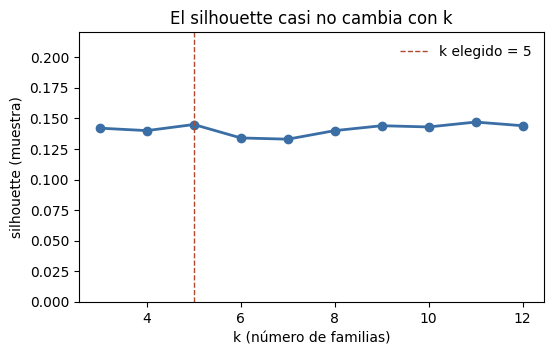

In [7]:
AZUL, ROJO, GRIS, VERDE = "#3A6EA5", "#B04A2E", "#75808E", "#2F6B4E"
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sil.index, sil.values, marker="o", color=AZUL, lw=2)
ax.axvline(C.K_FAMILIAS, color=ROJO, ls="--", lw=1, label=f"k elegido = {C.K_FAMILIAS}")
ax.set_ylim(0, sil.max() * 1.5)
ax.set_xlabel("k (número de familias)")
ax.set_ylabel("silhouette (muestra)")
ax.set_title("El silhouette casi no cambia con k")
ax.legend(frameon=False)
fig.savefig(C.FIGURAS / "03_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

El silhouette mide qué tan cerca está cada juego de su grupo comparado con el grupo vecino, y aquí queda casi plano, osea que ningún k separa mucho mejor que otro. El más alto es k=11 (0.147), pero k=5 (0.145) casi empata, entonces desempatamos con lo otro que se debe revisar al elegir k, que los grupos tengan sentido y se puedan nombrar. Por eso nos quedamos con 5.

En la celda siguiente hay dos controles. Un silhouette calculado con pocos ejes no se puede comparar con uno calculado con todas las columnas, porque al reducir ejes el número sube aunque no haya grupos. Se puede ver con las columnas barajadas, donde ya no hay ninguna relación entre etiquetas y aun así sale 0.10. O sea que PCA lo usamos para resumir, no porque mejore los grupos.

Aprendimos que k-Means siempre devuelve los k grupos que le pidas, existan o no, y que con un silhouette abajo de 0.25 hay que dudar de que existan. Aquí queda abajo, entonces los juegos son más un continuo y las familias sirven para describir el catálogo, no son grupos cerrados.

In [8]:
# Control 1: k-Means directo sobre las columnas de 0 y 1
matriz = M.to_numpy().astype(float)
crudo = KMeans(n_clusters=C.K_FAMILIAS, n_init=5, random_state=C.SEMILLA).fit_predict(matriz)
print("sin PCA:", round(silhouette_score(matriz[muestra], crudo[muestra]), 3))

# Control 2: cada columna barajada, con las mismas frecuencias pero sin relación entre etiquetas
rng_b = np.random.default_rng(C.SEMILLA)
barajada = np.column_stack([rng_b.permutation(matriz[:, j]) for j in range(matriz.shape[1])])
Z_b = PCA(n_components=C.N_COMPONENTES_PCA, random_state=C.SEMILLA).fit_transform(normalize(barajada))
grupos_b = KMeans(n_clusters=C.K_FAMILIAS, n_init=5, random_state=C.SEMILLA).fit_predict(Z_b)
print("con PCA y columnas barajadas:", round(silhouette_score(Z_b[muestra], grupos_b[muestra]), 3))
print("con PCA y datos reales:      ", sil[C.K_FAMILIAS])

sin PCA: 0.037


con PCA y columnas barajadas: 0.1
con PCA y datos reales:       0.145


In [9]:
km = KMeans(n_clusters=C.K_FAMILIAS, n_init=10, random_state=C.SEMILLA).fit(Z)
cluster = km.labels_

# Los números de grupo son arbitrarios, el nombre sale de las etiquetas que más sobresalen en cada familia
def limpiar(c):
    return c.replace("gen_", "").replace("tag_", "")

perfil = []
for g in range(C.K_FAMILIAS):
    m = cluster == g
    sobresale = (M[m].mean() - M.mean()).nlargest(8)
    unicas = list(dict.fromkeys(limpiar(c) for c in sobresale.index))[:4]
    conocidos = juegos[m].sort_values("total_resenas", ascending=False)["nombre"].head(3).tolist()
    perfil.append({"cluster": g, "juegos": int(m.sum()), "familia": " / ".join(unicas[:2]),
                   "etiquetas que sobresalen": ", ".join(unicas), "ejemplos": ", ".join(conocidos)})
perfil = pd.DataFrame(perfil).set_index("cluster")
perfil

,juegos,familia,etiquetas que sobresalen,ejemplos
cluster,,,,
0,12336,Action / Shooter,"Action, Shooter, Arcade, Platformer","Counter-Strike 2, PUBG: BATTLEGROUNDS, Grand T..."
1,8123,Adventure / Atmospheric,"Adventure, Atmospheric, Horror, Story Rich","Red Dead Redemption 2, The Forest, Lethal Company"
2,8794,Casual / Puzzle,"Casual, Puzzle, Relaxing, Cute","Human Fall Flat, The Sims™ 4, Balatro"
3,7480,RPG / Fantasy,"RPG, Fantasy, Adventure, Action RPG","Terraria, Black Myth: Wukong, ELDEN RING"
4,7835,Simulation / Strategy,"Simulation, Strategy, Management, Building","Dota 2, Garry's Mod, Stardew Valley"


## 4. Mapa PCA en 2D
Para dibujar usamos los dos primeros ejes de PCA, con una muestra para que el dibujo no quede saturado.

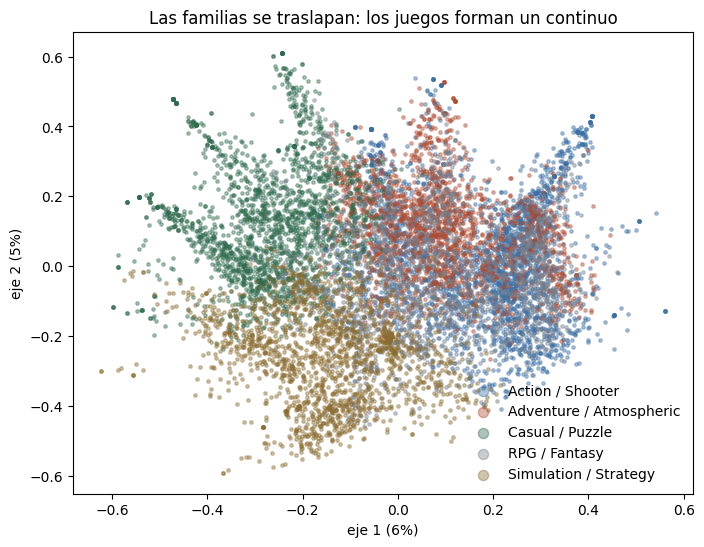

eje 1 | negativo: ['Casual', 'Casual', 'Simulation'] | positivo: ['Adventure', 'Action', 'Action']
eje 2 | negativo: ['Strategy', 'Strategy', 'Simulation'] | positivo: ['Adventure', 'Indie', 'Indie']


In [10]:
mapa = PCA(n_components=2, random_state=C.SEMILLA).fit(X)
xy = mapa.transform(X)
colores = [AZUL, ROJO, VERDE, GRIS, "#8C6D31", "#5B3F8C", "#2A7F8F"]

fig, ax = plt.subplots(figsize=(8, 6))
for g in range(C.K_FAMILIAS):
    m = np.where(cluster == g)[0]
    m = m[np.isin(m, muestra)]
    ax.scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.4, color=colores[g % len(colores)],
               label=perfil.loc[g, "familia"])
ax.set_xlabel(f"eje 1 ({mapa.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"eje 2 ({mapa.explained_variance_ratio_[1]:.0%})")
ax.set_title("Las familias se traslapan: los juegos forman un continuo")
ax.legend(frameon=False, markerscale=3)
fig.savefig(C.FIGURAS / "03_mapa_pca.png", dpi=150, bbox_inches="tight")
plt.show()

# Los ejes no tienen nombre, para leerlos se ve qué columnas pesan más en cada uno
pesos = pd.DataFrame(mapa.components_.T, index=[limpiar(c) for c in M.columns], columns=["eje 1", "eje 2"])
for eje in pesos:
    orden = pesos[eje].sort_values()
    print(eje, "| negativo:", list(orden.index[:3]), "| positivo:", list(orden.index[-3:]))

In [11]:
salida = pd.DataFrame({"appid": M.index, "cluster": cluster})
salida["familia"] = salida["cluster"].map(perfil["familia"])
salida.to_csv(C.OUTPUTS / "clusters.csv", index=False)
print("guardado:", C.OUTPUTS / "clusters.csv", "|", len(salida), "juegos")
salida["familia"].value_counts()

guardado: C:\Users\rodri\UFM\6toSemestre\DataScience\Data_science_final\outputs\clusters.csv | 44568 juegos


familia
Action / Shooter           12336
Casual / Puzzle             8794
Adventure / Atmospheric     8123
Simulation / Strategy       7835
RPG / Fantasy               7480
Name: count, dtype: int64

## Conclusión y limitaciones
Con un solo favorito el recomendador funciona bien, por ejemplo DOOM trae DOOM Eternal, Painkiller y Quake. La función similitud le da al notebook 05 el parecido de todos los juegos.

Con favoritos muy distintos hay que tener cuidado, porque el perfil es un promedio y puede quedar dominado por uno de ellos. Con Stardew Valley y Hollow Knight casi todo lo recomendado se parece a Hollow Knight. Una mejora sería recomendar por separado para cada favorito.

Las etiquetas las ponen los usuarios, así que pueden tener ruido o estar incompletas, y los juegos con pocas etiquetas se parecen poco a los demás. Además, los géneros y etiquetas con el mismo nombre, como Action o Casual, pesan doble. Lo dejamos así porque los dos describen el juego, pero sí empuja la similitud hacia esos temas.

Que un juego sea parecido no quiere decir que sea bueno, por eso en el notebook 05 se multiplica por la probabilidad de calidad del notebook 02.

Las familias son débiles con cualquier k, entonces las 5 sirven para describir el catálogo y no como grupos cerrados. El mapa solo muestra 11 % de la información y los 10 ejes conservan 35 %, así que lo que se ve ahí es una vista parcial.